# House Price Prediction Using Machine Learning

**Oasis Infobyte – Data Analytics Internship**

**Portfolio Task 5: House Price Prediction**

## Project Objective

The objective of this project is to develop a machine learning model that predicts residential property prices based on housing characteristics.

The project involves exploring the housing dataset, handling missing values, preparing numerical and categorical features, training regression models, and evaluating their predictive performance.

## Tools and Technologies

- Python
- Google Colab
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn

## Machine Learning Models

1. Linear Regression
2. Random Forest Regressor

## Evaluation Metrics

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


## Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the structure, quality and characteristics of the housing dataset.

This stage includes:

- Examining dataset dimensions and columns.
- Identifying missing values and duplicate records.
- Analysing descriptive statistics.
- Understanding the distribution of house prices.
- Exploring relationships between housing features and property prices.

In [2]:
df = pd.read_csv("/content/Housing.csv")

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst Five Records:")
display(df.head())

Dataset Shape: (545, 13)

Column Names:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

First Five Records:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [3]:
print("Dataset Information:")
df.info()

print("\nData Types:")
print(df.dtypes)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

Data Types:
price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories     

In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Total Missing Values:
0


In [5]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


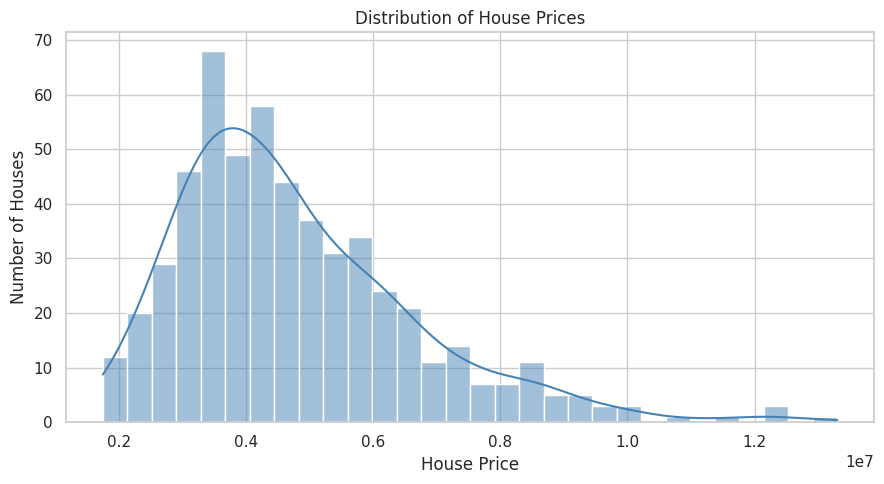

In [6]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="price",
    bins=30,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Number of Houses")

plt.tight_layout()
plt.show()

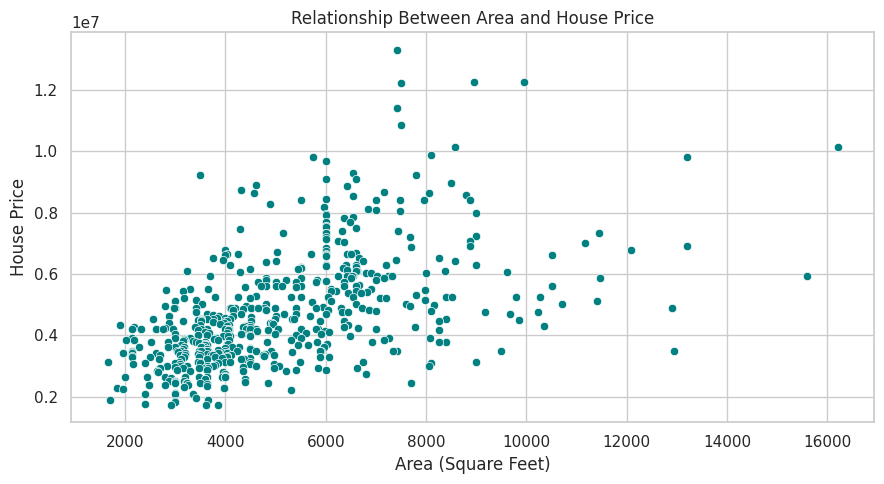

In [7]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="area",
    y="price",
    color="teal"
)

plt.title("Relationship Between Area and House Price")
plt.xlabel("Area (Square Feet)")
plt.ylabel("House Price")

plt.tight_layout()
plt.show()

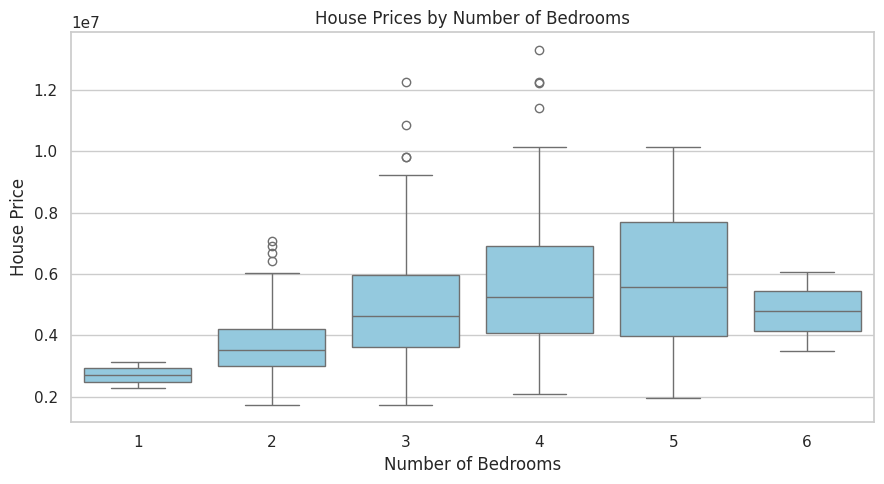

In [8]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="bedrooms",
    y="price",
    color="skyblue"
)

plt.title("House Prices by Number of Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("House Price")

plt.tight_layout()
plt.show()

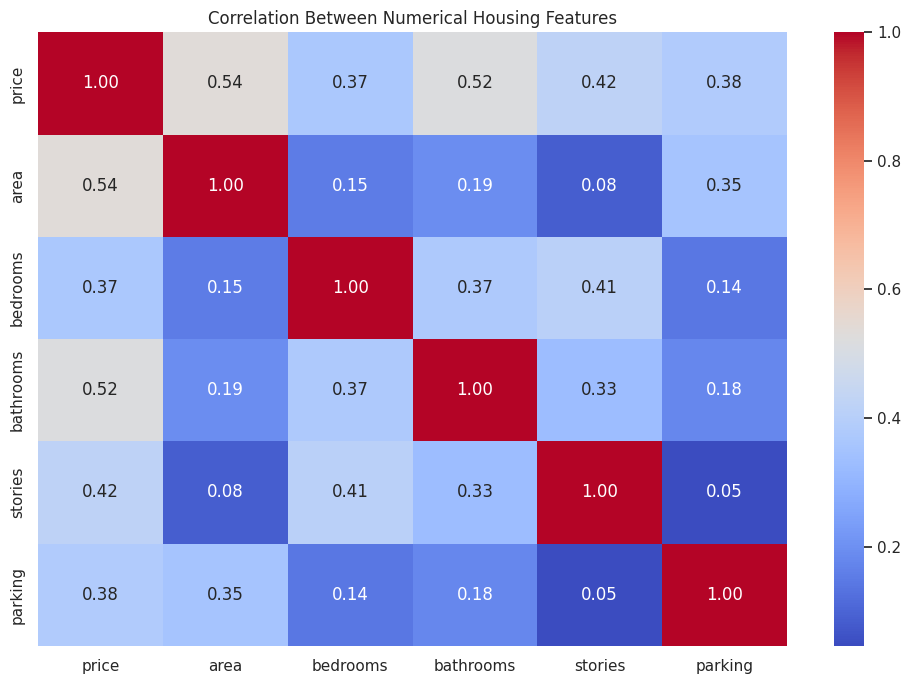

In [9]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Housing Features")

plt.tight_layout()
plt.show()

## Data Preprocessing

The housing dataset contains 545 records and 13 columns, with no missing values or duplicate rows.

The preprocessing stage prepares the data for machine learning by separating the target variable, splitting the dataset into training and testing sets, and encoding categorical variables.

The target variable is `price`, while the remaining columns are used as predictors.

An 80:20 train-test split will be applied to evaluate model performance on unseen data.

In [10]:
X = df.drop("price", axis=1)
y = df["price"]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (545, 12)
Target Shape: (545,)


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (436, 12)
Testing Data: (109, 12)


In [12]:
categorical_columns = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

Categorical Columns:
['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


In [13]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    ],
    remainder="passthrough"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Processed Training Shape: (436, 20)
Processed Testing Shape: (109, 20)


In [14]:
import numpy as np

print("Training Data Contains NaN:",
      np.isnan(X_train_processed).any())

print("Testing Data Contains NaN:",
      np.isnan(X_test_processed).any())

print("Training Records:", len(y_train))
print("Testing Records:", len(y_test))

Training Data Contains NaN: False
Testing Data Contains NaN: False
Training Records: 436
Testing Records: 109


## House Price Prediction Using Linear Regression

Linear Regression is a supervised machine learning algorithm used to predict continuous numerical values.

In this project, Linear Regression is used to estimate house prices based on property characteristics such as area, bedrooms, bathrooms, parking and furnishing status.

The model is trained using 80% of the housing dataset and evaluated on the remaining 20%.

Model performance is measured using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and R² Score.

In [15]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train_processed, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [16]:
lr_predictions = lr_model.predict(X_test_processed)

print("First 10 Predicted House Prices:")
print(lr_predictions[:10])

print("\nFirst 10 Actual House Prices:")
print(y_test.iloc[:10].values)

First 10 Predicted House Prices:
[5164653.90033958 7224722.29802165 3109863.24240343 4612075.32722563
 3294646.25725961 3532275.0955655  5611774.56836462 6368145.98732718
 2722856.9568999  2629405.61585792]

First 10 Actual House Prices:
[4060000 6650000 3710000 6440000 2800000 4900000 5250000 4543000 2450000
 3353000]


In [17]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

lr_mae = mean_absolute_error(y_test, lr_predictions)

lr_rmse = np.sqrt(
    mean_squared_error(y_test, lr_predictions)
)

lr_r2 = r2_score(y_test, lr_predictions)

print("===== LINEAR REGRESSION RESULTS =====")
print(f"Mean Absolute Error (MAE): {lr_mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): {lr_rmse:,.2f}")
print(f"R² Score: {lr_r2:.4f}")

===== LINEAR REGRESSION RESULTS =====
Mean Absolute Error (MAE): 970,043.40
Root Mean Squared Error (RMSE): 1,324,506.96
R² Score: 0.6529


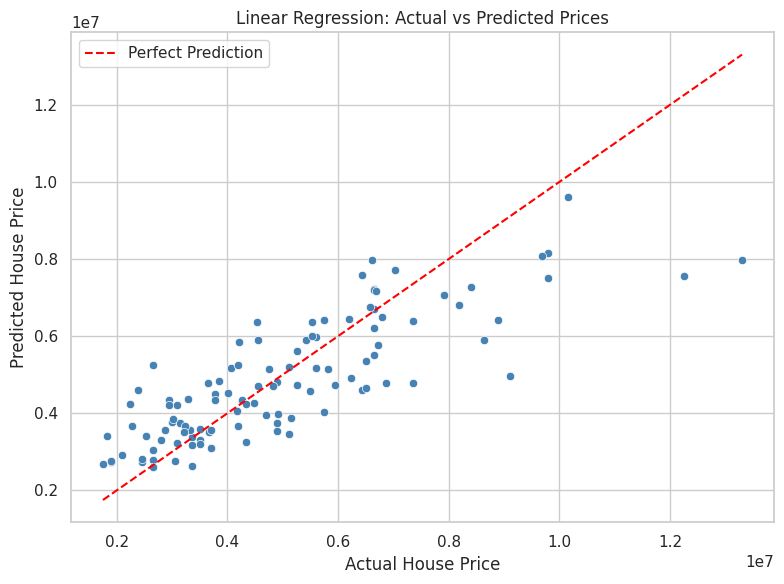

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=lr_predictions,
    color="steelblue"
)

min_price = min(y_test.min(), lr_predictions.min())
max_price = max(y_test.max(), lr_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Linear Regression: Actual vs Predicted Prices")
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.legend()

plt.tight_layout()
plt.show()

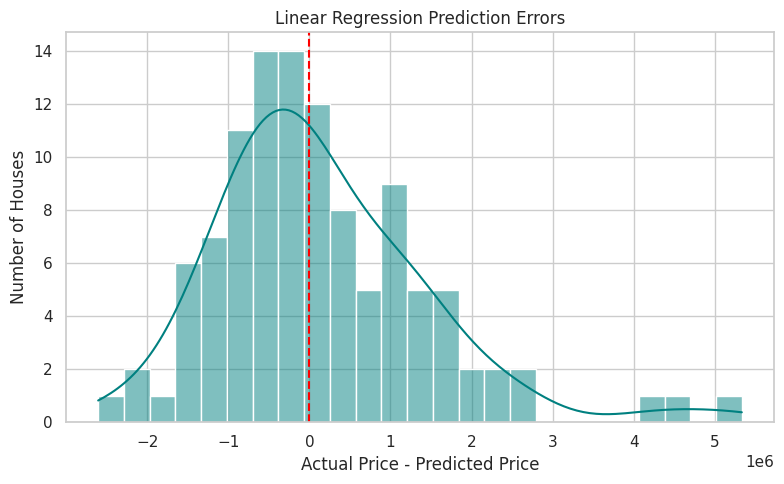

In [19]:
lr_errors = y_test - lr_predictions

plt.figure(figsize=(8, 5))

sns.histplot(
    lr_errors,
    bins=25,
    kde=True,
    color="teal"
)

plt.axvline(0, color="red", linestyle="--")

plt.title("Linear Regression Prediction Errors")
plt.xlabel("Actual Price - Predicted Price")
plt.ylabel("Number of Houses")

plt.tight_layout()
plt.show()

## House Price Prediction Using Random Forest Regression

Random Forest Regression is an ensemble machine learning algorithm that combines multiple decision trees to predict continuous numerical values.

In this project, Random Forest is used to predict house prices based on property characteristics, including area, bedrooms, bathrooms, parking and furnishing status.

The model is trained using the same training dataset as Linear Regression and evaluated on the same testing dataset.

Performance is measured using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and R² Score.

In [20]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [21]:
rf_predictions = rf_model.predict(X_test_processed)

print("First 10 Predicted House Prices:")
print(rf_predictions[:10])

print("\nFirst 10 Actual House Prices:")
print(y_test.iloc[:10].values)

First 10 Predicted House Prices:
[5383192.5   7158165.    3791326.875 4512515.    3710717.5   3479770.
 5102440.    5350730.    2548560.    2972882.5  ]

First 10 Actual House Prices:
[4060000 6650000 3710000 6440000 2800000 4900000 5250000 4543000 2450000
 3353000]


In [22]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

print("===== RANDOM FOREST RESULTS =====")
print(f"Mean Absolute Error (MAE): {rf_mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rf_rmse:,.2f}")
print(f"R² Score: {rf_r2:.4f}")

===== RANDOM FOREST RESULTS =====
Mean Absolute Error (MAE): 1,013,596.82
Root Mean Squared Error (RMSE): 1,396,543.92
R² Score: 0.6141


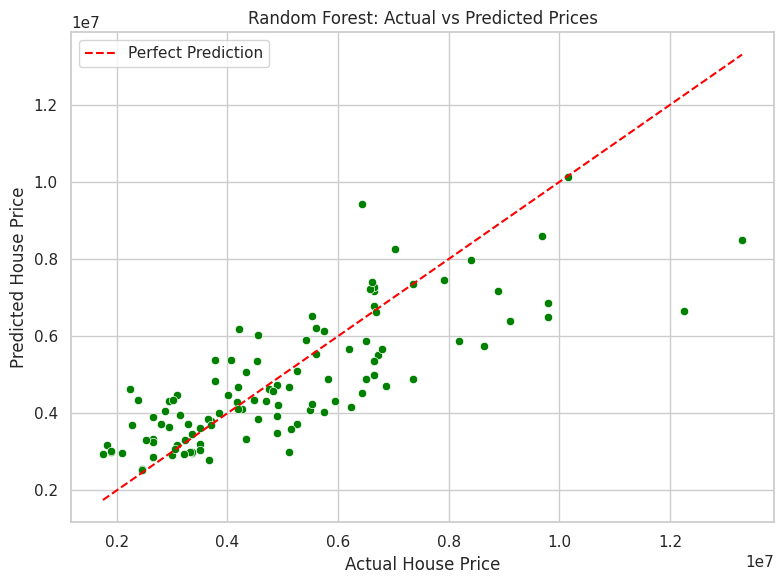

In [23]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=rf_predictions,
    color="green"
)

min_price = min(y_test.min(), rf_predictions.min())
max_price = max(y_test.max(), rf_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Random Forest: Actual vs Predicted Prices")
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.legend()

plt.tight_layout()
plt.show()

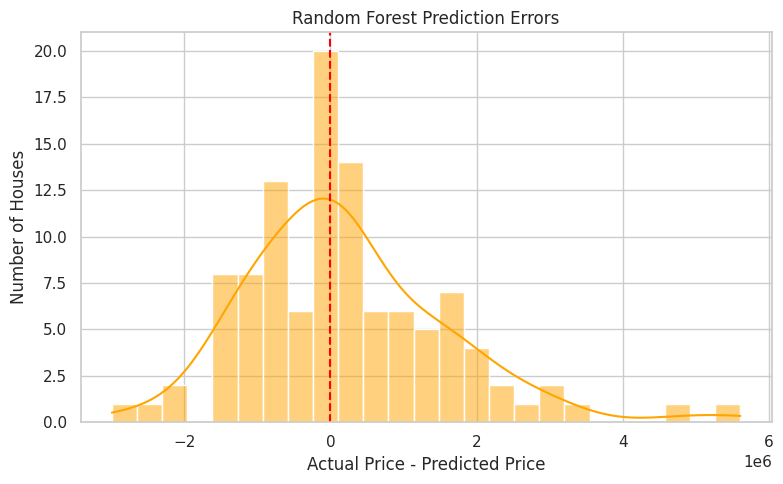

In [24]:
rf_errors = y_test - rf_predictions

plt.figure(figsize=(8, 5))

sns.histplot(
    rf_errors,
    bins=25,
    kde=True,
    color="orange"
)

plt.axvline(
    0,
    color="red",
    linestyle="--"
)

plt.title("Random Forest Prediction Errors")
plt.xlabel("Actual Price - Predicted Price")
plt.ylabel("Number of Houses")

plt.tight_layout()
plt.show()

In [25]:
#Compare Linear Regression and Random Forest
comparison_df = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [lr_mae, rf_mae],
    "RMSE": [lr_rmse, rf_rmse],
    "R2 Score": [lr_r2, rf_r2]
})

print("===== MODEL COMPARISON =====")
display(comparison_df.round(4))

===== MODEL COMPARISON =====


,Model,MAE,RMSE,R2 Score
0,Linear Regression,9.700434e+05,1.324507e+06,0.6529
1,Random Forest,1.013597e+06,1.396544e+06,0.6141


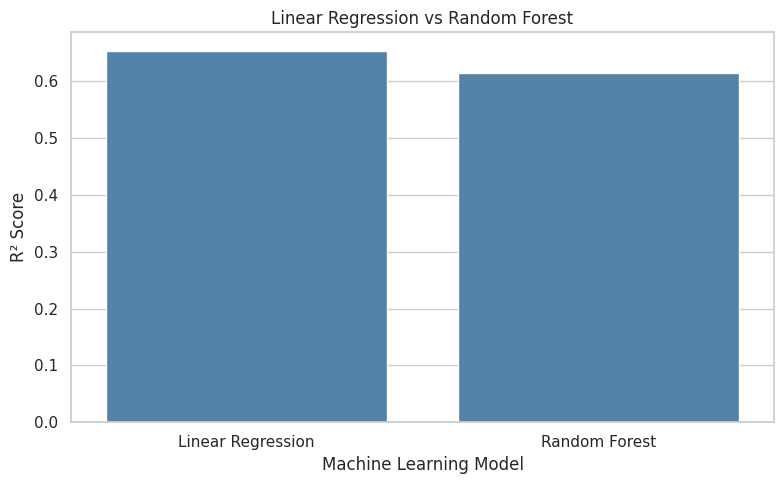

In [26]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="R2 Score",
    color="steelblue"
)

plt.title("Linear Regression vs Random Forest")
plt.ylabel("R² Score")
plt.xlabel("Machine Learning Model")

plt.tight_layout()
plt.show()

### Model Comparison Results and Observations

Two machine learning models, Linear Regression and Random Forest Regression, were trained and evaluated on the housing dataset.

Linear Regression achieved a Mean Absolute Error (MAE) of 970,043.40, Root Mean Squared Error (RMSE) of 1,324,506.96, and R² score of 0.6529.

Random Forest Regression achieved an MAE of approximately 1,013,597, RMSE of 1,396,544, and R² score of 0.6141.

Linear Regression performed better across all three evaluation metrics. It produced lower prediction errors and explained approximately 65.29% of the variation in house prices in the test dataset relative to the mean baseline.

Based on these results, Linear Regression was selected as the better-performing model for this experiment. Further evaluation using cross-validation and hyperparameter tuning would help determine whether this advantage is consistent across different data splits.

## Step 10: Feature Importance Analysis

Feature importance analysis helps identify which housing characteristics contribute most to the predictions generated by the Random Forest model.

The analysis examines features such as area, bedrooms, bathrooms, parking, furnishing status and other property characteristics.

Random Forest feature importance measures how much each feature contributes to reducing prediction error within the fitted trees.

These importance values describe the model's behaviour and should not be interpreted as evidence of causal relationships.

In [27]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get Random Forest feature importance
importances = rf_model.feature_importances_

# Create feature importance DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort by importance
feature_importance_df = (
    feature_importance_df
    .sort_values(by="Importance", ascending=False)
)

print("Feature Importance Scores:")
display(feature_importance_df)

Feature Importance Scores:


,Feature,Importance
15,remainder__area,0.463979
17,remainder__bathrooms,0.152534
19,remainder__parking,0.056468
18,remainder__stories,0.055464
16,remainder__bedrooms,0.045147
14,categorical__furnishingstatus_unfurnished,0.035919
9,categorical__airconditioning_yes,0.031559
8,categorical__airconditioning_no,0.028545
5,categorical__basement_yes,0.017374
4,categorical__basement_no,0.016374


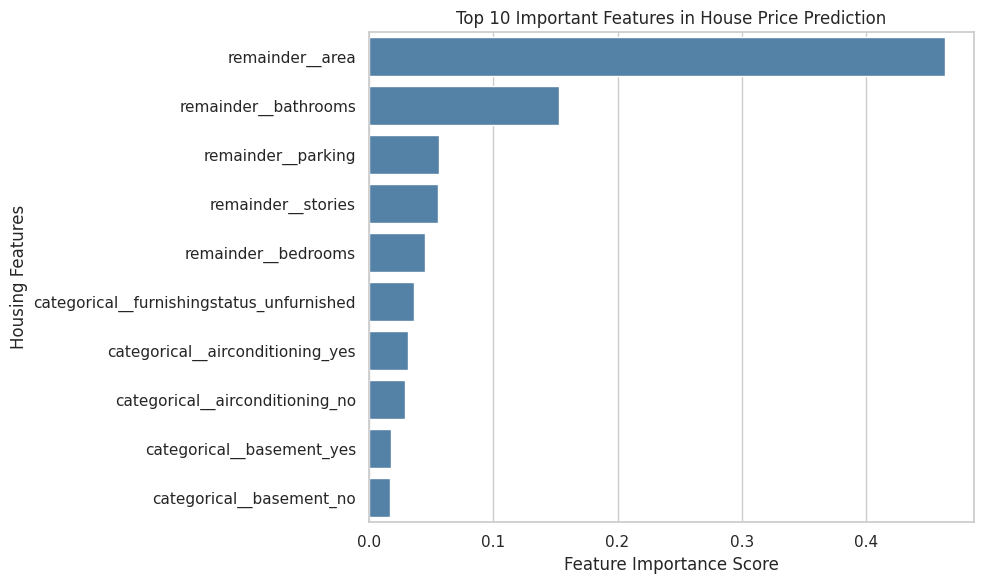

In [28]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance_df.head(10),
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Top 10 Important Features in House Price Prediction")
plt.xlabel("Feature Importance Score")
plt.ylabel("Housing Features")

plt.tight_layout()
plt.show()

In [29]:
# Group encoded features by their original column
original_importance = {}

for col in X_train.columns:
    if col in categorical_columns:
        prefix = f"categorical__{col}_"

        mask = feature_importance_df[
            "Feature"
        ].str.startswith(prefix)

    else:
        mask = (
            feature_importance_df["Feature"]
            == f"remainder__{col}"
        )

    original_importance[col] = (
        feature_importance_df.loc[
            mask, "Importance"
        ].sum()
    )

original_importance_df = pd.DataFrame({
    "Feature": list(original_importance.keys()),
    "Importance": list(original_importance.values())
}).sort_values(
    "Importance", ascending=False
)

print("Original Housing Feature Importance:")
display(original_importance_df)

Original Housing Feature Importance:


,Feature,Importance
0,area,0.463979
2,bathrooms,0.152534
8,airconditioning,0.060104
11,furnishingstatus,0.057007
9,parking,0.056468
3,stories,0.055464
1,bedrooms,0.045147
6,basement,0.033747
10,prefarea,0.029020
7,hotwaterheating,0.018195


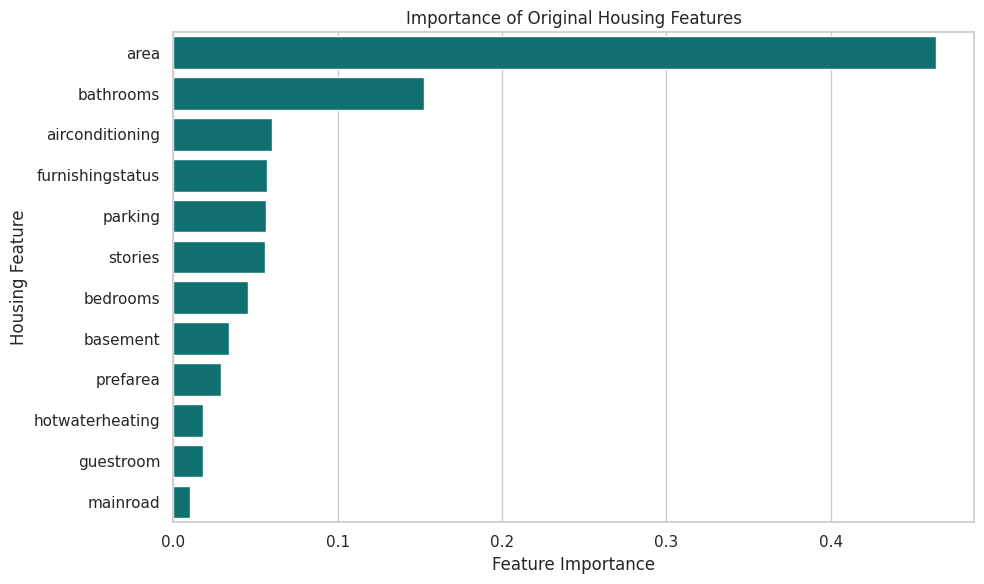

In [30]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=original_importance_df,
    x="Importance",
    y="Feature",
    color="teal"
)

plt.title("Importance of Original Housing Features")
plt.xlabel("Feature Importance")
plt.ylabel("Housing Feature")

plt.tight_layout()
plt.show()

In [31]:
print("Top 5 Most Important Housing Features:")

display(original_importance_df.head(5))

Top 5 Most Important Housing Features:


,Feature,Importance
0,area,0.463979
2,bathrooms,0.152534
8,airconditioning,0.060104
11,furnishingstatus,0.057007
9,parking,0.056468


### Feature Importance Results and Observations

The Random Forest feature importance analysis identified area as the most influential variable, with an importance score of 0.463979 (46.40%).

Bathrooms ranked second with an importance score of 0.152534 (15.25%). Air conditioning, furnishing status and parking contributed approximately 6.01%, 5.70% and 5.65%, respectively.

These findings suggest that property size and bathroom availability are particularly influential in the Random Forest model's predictions.

The importance scores describe how the trained model uses housing characteristics. They do not establish causal effects or indicate how much a feature directly increases property value.

## Final House Price Predictions

Linear Regression was selected as the better-performing model based on its lower prediction errors and higher R² score on the test dataset.

The final prediction analysis compares actual house prices with predicted values, calculates absolute prediction errors, and exports the results for further examination.

In [32]:
final_predictions = pd.DataFrame({
    "Actual_Price": y_test.to_numpy(),
    "Predicted_Price": lr_predictions
})

final_predictions["Absolute_Error"] = (
    final_predictions["Actual_Price"] -
    final_predictions["Predicted_Price"]
).abs()

final_predictions["Percentage_Error"] = np.where(
    final_predictions["Actual_Price"] != 0,
    final_predictions["Absolute_Error"] /
    final_predictions["Actual_Price"] * 100,
    np.nan
)

print("Final House Price Predictions:")
display(final_predictions.head(10))

Final House Price Predictions:


,Actual_Price,Predicted_Price,Absolute_Error,Percentage_Error
0,4060000,5.164654e+06,1.104654e+06,27.208224
1,6650000,7.224722e+06,5.747223e+05,8.642441
2,3710000,3.109863e+06,6.001368e+05,16.176193
3,6440000,4.612075e+06,1.827925e+06,28.383923
4,2800000,3.294646e+06,4.946463e+05,17.665938
5,4900000,3.532275e+06,1.367725e+06,27.912753
6,5250000,5.611775e+06,3.617746e+05,6.890944
7,4543000,6.368146e+06,1.825146e+06,40.174906
8,2450000,2.722857e+06,2.728570e+05,11.137019
9,3353000,2.629406e+06,7.235944e+05,21.580507


In [33]:
print("===== FINAL MODEL SUMMARY =====")

print("Selected Model: Linear Regression")
print("Total Test Records:", len(y_test))

print(f"MAE: {lr_mae:,.2f}")
print(f"RMSE: {lr_rmse:,.2f}")
print(f"R² Score: {lr_r2:.4f}")

print(
    "Mean Absolute Percentage Error:",
    f"{final_predictions['Percentage_Error'].mean():.2f}%"
)

===== FINAL MODEL SUMMARY =====
Selected Model: Linear Regression
Total Test Records: 109
MAE: 970,043.40
RMSE: 1,324,506.96
R² Score: 0.6529
Mean Absolute Percentage Error: 21.04%


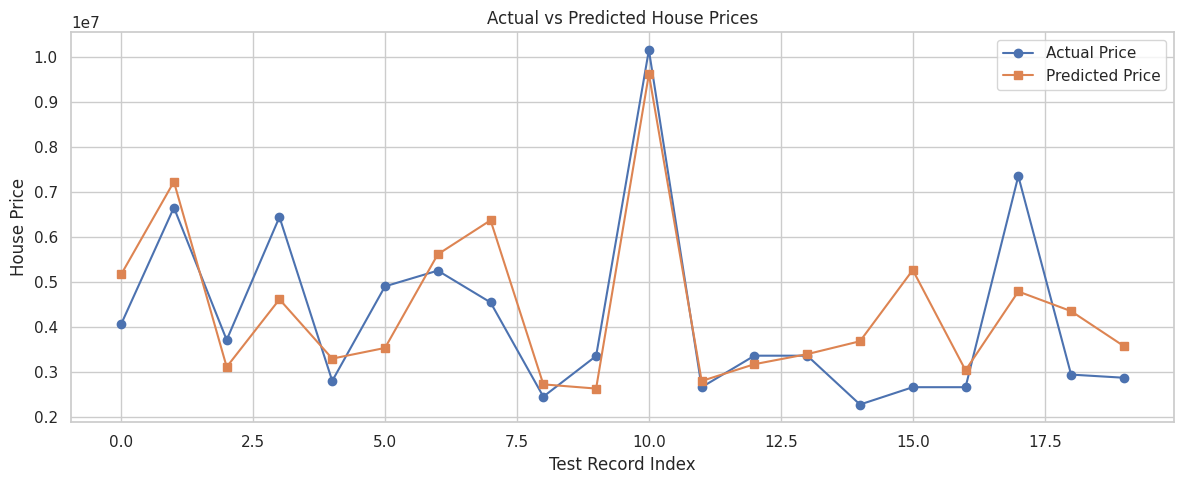

In [34]:
plt.figure(figsize=(12, 5))

sample_results = final_predictions.head(20)

plt.plot(
    sample_results.index,
    sample_results["Actual_Price"],
    marker="o",
    label="Actual Price"
)

plt.plot(
    sample_results.index,
    sample_results["Predicted_Price"],
    marker="s",
    label="Predicted Price"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Test Record Index")
plt.ylabel("House Price")
plt.legend()

plt.tight_layout()
plt.show()

In [35]:
output_file = "House_Price_Predictions.csv"

final_predictions.to_csv(
    output_file,
    index=False
)

print("Prediction results saved successfully!")

Prediction results saved successfully!


In [36]:
from google.colab import files

files.download("House_Price_Predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

This project developed and compared two machine learning models, Linear Regression and Random Forest Regression, to predict residential property prices using a housing dataset containing 545 records and 13 columns.

Exploratory Data Analysis confirmed that the dataset contained no missing values or duplicate records. Categorical variables were encoded, and the dataset was divided into training and testing subsets using an 80:20 split.

Linear Regression achieved an MAE of 970,043.40, RMSE of 1,324,506.96 and R² score of 0.6529. Random Forest produced an MAE of approximately 1,013,597, RMSE of 1,396,544 and R² score of 0.6141.

Linear Regression performed better across all three evaluation metrics and was selected as the preferred model for this experiment.

Random Forest feature importance analysis identified area as the most influential feature (46.40%), followed by bathrooms (15.25%), air conditioning (6.01%), furnishing status (5.70%) and parking (5.65%).

The results demonstrate how regression techniques can estimate residential property prices using structured housing data. However, prediction errors remain, and model performance may vary across different datasets.

## Limitations

- The dataset contains only 545 housing records.
- The models were evaluated using a single train-test split.
- Important factors such as detailed location, property age and neighbourhood characteristics were not included.
- Random Forest hyperparameters were not systematically optimised.
- The dataset may not represent current housing market conditions.

## Future Scope

Future improvements could include hyperparameter tuning, cross-validation, additional housing features and comparisons with other regression algorithms such as Gradient Boosting.

More detailed location and property information could also improve the model's ability to capture differences in residential property prices.